# 02 · Modelos y evaluación

Entrada: `data/autos_clean.csv` (sale del notebook 01).

Pregunta: ¿qué tan bien se estima el precio de un auto usado a partir de su aviso?

Plan (propuesta, diapositiva 8):

1. **Split train/test agrupado por `grupo_gemelo`**, una sola vez: un mismo auto publicado dos
   veces nunca queda de los dos lados.
2. **Modelo base:** mediana de log(precio) del modelo (si el modelo no está en train, la de la marca).
3. **Ridge y Lasso sobre log(precio)**, eligiendo hiperparámetros con **K-fold agrupado** solo en train:
   - `alpha` (regularización),
   - `umbral` de modelos raros (un modelo con menos avisos que el umbral en train pasa a "otro de la marca"),
   - con o sin la interacción **antigüedad × marca** (depreciación propia de cada marca), pero solo
     para marcas con al menos 100 o 300 avisos en train; el resto usa la pendiente común.
4. **Árbol de decisión** como comparación no lineal (`max_depth` y `min_samples_leaf` por K-fold).
5. **Evaluación en test** (se mira una sola vez, al final): RMSE, MAE y R².
6. **Curva de aprendizaje** del mejor modelo: ¿más avisos mejorarían la tasación?

Variables: antigüedad, log(km), marca, modelo, tipo de vendedor e indicios del título
(cilindrada, transmisión, combustible; el faltante es la categoría `sin_dato`).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import cloudpickle
import preparar
from preparar import Preparar, COLS, CAT_TITULO
cloudpickle.register_pickle_by_value(preparar)  # para que los procesos de n_jobs=-1 la encuentren

DATA, FIGS = Path("../data"), Path("figuras")
SEMILLA = 42
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#5f5e58", "#e4e3dd"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10,
})

df = pd.read_csv(DATA / "autos_clean.csv")
df[CAT_TITULO] = df[CAT_TITULO].astype("string").fillna("sin_dato")
df.shape

(16581, 20)

## 1. Split train/test agrupado

In [2]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_tr, idx_te = next(split.split(df, groups=df["grupo_gemelo"]))
train, test = df.iloc[idx_tr].reset_index(drop=True), df.iloc[idx_te].reset_index(drop=True)

compartidos = set(train["grupo_gemelo"]) & set(test["grupo_gemelo"])
assert not compartidos, "hay gemelos de los dos lados"
print(f"train: {len(train)} · test: {len(test)} · grupos compartidos: {len(compartidos)}")

y_tr, y_te = train["log_precio"].to_numpy(), test["log_precio"].to_numpy()

train: 13265 · test: 3316 · grupos compartidos: 0


## 2. Métricas

El modelo predice log(precio). Se reporta:
- **en log:** RMSE y R² (lo que optimiza el modelo);
- **en dólares:** MAE y RMSE de `exp(predicción)`, y el **error porcentual mediano**, que es
  lo que entiende alguien que tasa un auto.

Ojo: si el error en log es simétrico, `exp(predicción)` estima la **mediana** del precio para ese
auto, no la media. Para un tasador es lo razonable (la mitad de los avisos parecidos pide más y la
mitad menos), pero hay que tenerlo en cuenta al leer el MAE y el RMSE en dólares.

In [3]:
def metricas(y_log, pred_log, nombre):
    real, pred = np.exp(y_log), np.exp(pred_log)
    return {
        "modelo": nombre,
        "RMSE_log": mean_squared_error(y_log, pred_log) ** 0.5,
        "R2_log": r2_score(y_log, pred_log),
        "MAE_USD": mean_absolute_error(real, pred),
        "RMSE_USD": mean_squared_error(real, pred) ** 0.5,
        "error_%_mediano": np.median(np.abs(pred / real - 1)) * 100,
    }

## 3. Modelo base: mediana por modelo

Es la tasación "de sentido común": mirar cuánto se pide por ese modelo. Si la regresión no le gana,
no aporta nada.

In [4]:
med_modelo = train.groupby(["marca", "modelo"])["log_precio"].median()
med_marca = train.groupby("marca")["log_precio"].median()
med_global = np.median(y_tr)

def base(d):
    p = d.set_index(["marca", "modelo"]).index.map(med_modelo).to_numpy(dtype=float, copy=True)
    falta = np.isnan(p)
    p[falta] = d.loc[falta, "marca"].map(med_marca).fillna(med_global).to_numpy()
    return p

# Para comparar con la regresión de forma justa, el base también se evalúa por K-fold agrupado en train
cv = GroupKFold(n_splits=5)
cv_base = []
for a, b in cv.split(train, groups=train["grupo_gemelo"]):
    tr_k, va_k = train.iloc[a], train.iloc[b]
    mm = tr_k.groupby(["marca", "modelo"])["log_precio"].median()
    mb = tr_k.groupby("marca")["log_precio"].median()
    p = va_k.set_index(["marca", "modelo"]).index.map(mm).to_numpy(dtype=float, copy=True)
    f = np.isnan(p)
    p[f] = va_k.loc[f, "marca"].map(mb).fillna(tr_k["log_precio"].median()).to_numpy()
    cv_base.append(mean_squared_error(va_k["log_precio"], p) ** 0.5)
print(f"Base · RMSE_log en CV: {np.mean(cv_base):.4f} ± {np.std(cv_base):.4f}")

Base · RMSE_log en CV: 0.3335 ± 0.0096


## 4. Preparación de variables

`Preparar` hace, **con los conteos de train de cada fold** (para no filtrar información de validación):

- marca y modelo con menos de `umbral` avisos → `"<marca>|otro"` y `"otra_marca"`;
- one-hot de las categóricas (lo que aparece solo en validación/test queda en ceros);
- si `interaccion=True`, una columna `antigüedad × marca` por marca: cada marca tiene su propia
  pendiente de depreciación.

Las numéricas se estandarizan para que la regularización trate a todas las variables por igual.

In [5]:
# La clase vive en notebooks/preparar.py (la usa también el notebook 03).
X_tr, X_te = train[COLS], test[COLS]
grupos_tr = train["grupo_gemelo"]

## 5. Selección de hiperparámetros (K-fold agrupado, solo train)

In [6]:
UMBRALES = [1, 2, 3, 5, 10, 20]  # 1 = sin agrupar
# Lasso: en una corrida anterior (2026-11-16, ~3 h, con la limpieza de ese momento) se buscó
# umbral ∈ {1, 2, 3, 5}, interacción sí/no y alpha ∈ logspace(-6, -4, 5); ganó umbral 2, sin
# interacción, alpha = 10^-4,5 ≈ 3,16e-5. Con alpha tan chico cada ajuste tarda ~4 min (descenso
# por coordenadas sobre ~850 columnas), así que Lasso queda fijo en esos valores y solo se recalcula
# su error de validación. Ridge y el árbol mantienen la búsqueda completa.
ALPHAS = np.logspace(-2, 3, 11)
grillas = {
    # Pendiente propia por marca solo para marcas con muchos avisos: con 1 o 2 avisos la pendiente
    # se estima sobre casi nada. En una versión anterior la interacción para todas las marcas
    # empataba en validación (0,2193 contra 0,2194) pero en test predecía precios absurdos para
    # marcas raras (RMSE en dólares de 34.000).
    "Ridge": (Ridge(), [
        {"prep__umbral": UMBRALES, "prep__interaccion": [False], "reg__alpha": ALPHAS},
        {"prep__umbral": UMBRALES, "prep__interaccion": [True], "prep__umbral_interaccion": [100, 300],
         "reg__alpha": ALPHAS},
    ]),
    "Lasso": (Lasso(max_iter=20_000), {"prep__umbral": [2], "prep__interaccion": [False],
                                       "reg__alpha": [10 ** -4.5]}),
    # El árbol no usa pendientes: la interacción no aporta y la escala de las variables no importa.
    "Árbol de decisión": (DecisionTreeRegressor(random_state=SEMILLA),
                          {"prep__umbral": [1, 10], "prep__interaccion": [False],
                           "reg__max_depth": [10, 15, 20, 30, None],
                           "reg__min_samples_leaf": [1, 5, 10, 20]}),
}
busquedas = {}
for nombre, (est, grilla) in grillas.items():
    pipe = Pipeline([("prep", Preparar()), ("reg", est)])
    gs = GridSearchCV(pipe, grilla, cv=GroupKFold(n_splits=5),
                      scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
    gs.fit(X_tr, y_tr, groups=grupos_tr)
    busquedas[nombre] = gs
    i = gs.best_index_
    print(f"{nombre}: mejor {gs.best_params_}\n"
          f"   RMSE_log CV {-gs.best_score_:.4f} (train {-gs.cv_results_['mean_train_score'][i]:.4f})")

Ridge: mejor {'prep__interaccion': True, 'prep__umbral': 1, 'prep__umbral_interaccion': 300, 'reg__alpha': np.float64(0.31622776601683794)}
   RMSE_log CV 0.2181 (train 0.1790)


Lasso: mejor {'prep__interaccion': False, 'prep__umbral': 2, 'reg__alpha': 3.1622776601683795e-05}
   RMSE_log CV 0.2232 (train 0.2001)


Árbol de decisión: mejor {'prep__interaccion': False, 'prep__umbral': 1, 'reg__max_depth': 30, 'reg__min_samples_leaf': 1}
   RMSE_log CV 0.3018 (train 0.1566)


### ¿Qué aporta cada decisión?

Mejor RMSE de validación de Ridge para cada combinación de umbral y pendiente por marca (mínimo sobre
`alpha`). Solo Ridge: Lasso quedó fijo (ver la celda anterior).

Debajo, el árbol: RMSE de validación según profundidad y tamaño mínimo de hoja (mínimo sobre el
umbral), y la brecha con el error de train.

In [7]:
r = pd.DataFrame(busquedas["Ridge"].cv_results_)
r["pendiente"] = np.where(r["param_prep__interaccion"].astype(bool),
                          "propia, marcas ≥ " + r["param_prep__umbral_interaccion"].astype(str), "común")
tabla_cv = (r.assign(RMSE_log=-r["mean_test_score"])
             .groupby(["pendiente", "param_prep__umbral"])["RMSE_log"].min()
             .unstack().round(4))
tabla_cv.index = [f"Ridge · pendiente {i}" for i in tabla_cv.index]
tabla_cv.columns = [f"umbral {u}" for u in tabla_cv.columns]
display(tabla_cv)

r = pd.DataFrame(busquedas["Árbol de decisión"].cv_results_)
r["max_depth"] = r["param_reg__max_depth"].astype(object).fillna("sin límite").astype(str)
mejor_arbol = (r.assign(valid=-r["mean_test_score"], train=-r["mean_train_score"])
                .sort_values("valid").drop_duplicates(["max_depth", "param_reg__min_samples_leaf"]))
tabla_arbol = (mejor_arbol.pivot(index="max_depth", columns="param_reg__min_samples_leaf", values="valid")
                .round(4))
tabla_arbol.columns = [f"hoja ≥ {c}" for c in tabla_arbol.columns]
display(tabla_arbol)
print("Brecha train/validación del mejor árbol:",
      mejor_arbol.iloc[0][["train", "valid"]].astype(float).round(4).to_dict())

,umbral 1,umbral 2,umbral 3,umbral 5,umbral 10,umbral 20
Ridge · pendiente común,0.2194,0.2230,0.2287,0.2336,0.2448,0.2645
"Ridge · pendiente propia, marcas ≥ 100.0",0.2185,0.2220,0.2278,0.2324,0.2426,0.2621
"Ridge · pendiente propia, marcas ≥ 300.0",0.2181,0.2218,0.2277,0.2324,0.2428,0.2624


,hoja ≥ 1,hoja ≥ 5,hoja ≥ 10,hoja ≥ 20
max_depth,,,,
10,0.3528,0.3521,0.3562,0.3623
15,0.3235,0.3271,0.3270,0.3399
20,0.3103,0.3158,0.3188,0.3300
30,0.3018,0.3094,0.3145,0.3307
sin límite,0.3071,0.3133,0.3160,0.3307


Brecha train/validación del mejor árbol: {'train': 0.1566, 'valid': 0.3018}


## 6. Evaluación final en test

Se reentrena cada modelo con **todo train** y los hiperparámetros elegidos (`GridSearchCV` ya lo hace)
y se mide **una sola vez** en test.

En una versión anterior del proyecto, mirar test motivó dos cambios: la regla de limpieza de avisos en
pesos (notebook 01) y limitar la pendiente propia a las marcas grandes (celda de la búsqueda de
hiperparámetros; el umbral de 100 o 300 avisos lo elige la validación cruzada). El resultado final de
esta celda se midió una vez, después de fijar todo lo anterior.

In [8]:
res = [metricas(y_te, base(test), "Base: mediana por modelo")]
for nombre, gs in busquedas.items():
    res.append(metricas(y_te, gs.predict(X_te), nombre))
resultados = pd.DataFrame(res).set_index("modelo").round(
    {"RMSE_log": 4, "R2_log": 3, "MAE_USD": 0, "RMSE_USD": 0, "error_%_mediano": 1})
resultados.to_csv(DATA / "resultados_test.csv")
resultados

,RMSE_log,R2_log,MAE_USD,RMSE_USD,error_%_mediano
modelo,,,,,
Base: mediana por modelo,0.3324,0.682,4181.0,8036.0,15.7
Ridge,0.2183,0.863,2506.0,5203.0,9.5
Lasso,0.2280,0.850,2657.0,5688.0,9.9
Árbol de decisión,0.3150,0.714,3555.0,8240.0,12.7


## 7. Curva de aprendizaje

Con ~13.000 avisos de train y ~1.100 columnas, ¿el modelo está limitado por la cantidad de datos?
Se reentrena el mejor modelo con fracciones crecientes de train y se mide en validación
(mismo K-fold agrupado). Si la curva de validación sigue bajando al final, más avisos ayudarían;
si ya está plana, el límite es lo que el aviso no dice (estado, equipamiento, versión exacta).

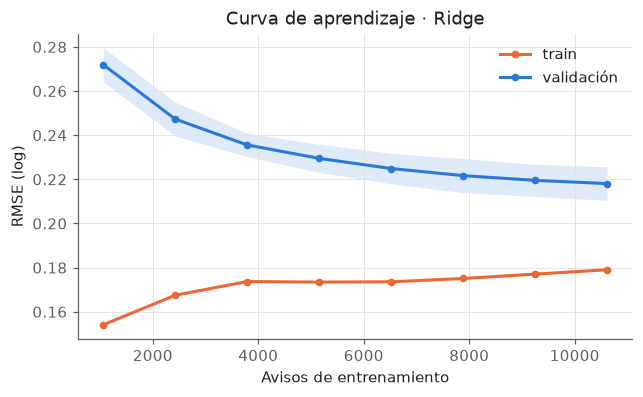

,avisos_train,RMSE_train,RMSE_valid,desvío_valid
0,1061,0.1541,0.2719,0.0077
1,2425,0.1675,0.2473,0.0077
2,3790,0.1737,0.2356,0.0053
3,5154,0.1734,0.2295,0.0064
4,6518,0.1736,0.2249,0.0069
5,7883,0.1751,0.2217,0.0077
6,9247,0.1771,0.2195,0.0073
7,10612,0.1790,0.2181,0.0076


In [9]:
mejor = min(busquedas, key=lambda n: -busquedas[n].best_score_)
tamanos, sc_tr, sc_va = learning_curve(
    busquedas[mejor].best_estimator_, X_tr, y_tr, groups=grupos_tr, cv=GroupKFold(n_splits=5),
    train_sizes=np.linspace(0.1, 1.0, 8), scoring="neg_root_mean_squared_error", n_jobs=-1,
    shuffle=True, random_state=SEMILLA)  # sin shuffle toma los primeros avisos del CSV, que vienen ordenados
curva = pd.DataFrame({"avisos_train": tamanos, "RMSE_train": -sc_tr.mean(axis=1),
                      "RMSE_valid": -sc_va.mean(axis=1), "desvío_valid": sc_va.std(axis=1)})

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curva["avisos_train"], curva["RMSE_train"], marker="o", markersize=4, color=SERIES[1], label="train")
ax.plot(curva["avisos_train"], curva["RMSE_valid"], marker="o", markersize=4, color=SERIES[0], label="validación")
ax.fill_between(curva["avisos_train"], curva["RMSE_valid"] - curva["desvío_valid"],
                curva["RMSE_valid"] + curva["desvío_valid"], color=SERIES[0], alpha=0.15, linewidth=0)
ax.set(xlabel="Avisos de entrenamiento", ylabel="RMSE (log)", title=f"Curva de aprendizaje · {mejor}")
ax.legend(frameon=False)
fig.savefig(FIGS / "06_curva_aprendizaje.png")
plt.show()
curva.round(4)

## 8. Guardar predicciones de test

Para el notebook 03 (residuos y depreciación): residuo = log(precio publicado) − log(precio predicho).

In [10]:
pred = busquedas[mejor].predict(X_te)
salida = test[["item_id", "marca", "modelo", "anio", "km", "precio_usd", "tipo_vendedor"]].assign(
    pred_usd=np.exp(pred).round(0), residuo=y_te - pred)
salida.to_csv(DATA / "predicciones_test.csv", index=False)

params = {k.split("__", 1)[1]: (v.item() if hasattr(v, "item") else v)
          for k, v in busquedas[mejor].best_params_.items()}
(DATA / "mejor_modelo.json").write_text(json.dumps({"modelo": mejor, **params}, indent=2), encoding="utf-8")
print(f"Modelo guardado para residuos: {mejor} {busquedas[mejor].best_params_}")

Modelo guardado para residuos: Ridge {'prep__interaccion': True, 'prep__umbral': 1, 'prep__umbral_interaccion': 300, 'reg__alpha': np.float64(0.31622776601683794)}
